In [1]:
%load_ext autoreload
%autoreload 2
import torch

In [2]:
import captum
from captum.attr import IntegratedGradients, Occlusion, LayerGradCam, LayerAttribution, GuidedGradCam, Saliency, DeepLift, GuidedBackprop, InputXGradient
from matplotlib.colors import LinearSegmentedColormap
from captum.attr import visualization as viz
import matplotlib.pyplot as plt


In [3]:
from pytorch_grad_cam import GradCAM, \
    ScoreCAM, \
    GradCAMPlusPlus, \
    AblationCAM, \
    XGradCAM, \
    EigenCAM, \
    EigenGradCAM, \
    LayerCAM, \
    FullGrad, \
    GradCAMElementWise
from pytorch_grad_cam import GuidedBackpropReLUModel
from pytorch_grad_cam.utils.image import show_cam_on_image, \
    preprocess_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import warnings


In [4]:

import os
import torch.backends.cudnn as cudnn
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import time
from datetime import datetime 
import pdb
import yaml
import sys
import glob
import shutil
import tqdm
import imageio

sys.path.append('../../MARS')
import MARS.run_lars.code_3d.utils
from MARS.run_lars.code_3d.dataset import get_datasets_3d, dataset_3d, dataset_3d_center
from MARS.run_lars.code_3d.utils import model_prediction, my_model

def load_config():
    if len(sys.argv) < 2:
        print("Usage: python script.py <config.yaml>")
        sys.exit(1)

    config_path = sys.argv[1]
    with open(config_path, "r") as f:
        config = yaml.safe_load(f)
    return config

def load_config_notebook():
    config = '/gpfs/home/kn2347/MARS/MARS/scripts/run_lars/predictions/3D_all_seeds_prediction/config.yaml'
    with open(config, "r") as f:
        config_data = yaml.safe_load(f)
    return config_data

def set_defaults_config():
    default_dict = {
        'postfilter_fwhm_xy_mm': None,
        'normalize_mean': None,
        'normalize_std': None,
        'ct_mode': None,
        'ct_bone_seg_dilation_erosion_pixels': None,
        'ct_bone_seg_dilation_alone_pixels': None
    }


    for key, value in default_dict.items():
        if key not in args:
            args[key] = value

args = load_config_notebook()
set_defaults_config()

In [5]:
model_path_pattern = f'/gpfs/data/mayerhoeferlab/projects/myeloma/results/train_3d/train_all_seeds_11-16-25/checkpoint_seed*_run0_best.pth'
#model_path_pattern = f'/gpfs/data/mayerhoeferlab/projects/myeloma/results/train/train_all_seeds_11-8-25/checkpoint_seed*_run*_best.pth'
rt = f'/gpfs/data/mayerhoeferlab/projects/myeloma/results/3D_all_seeds_prediction'
dataset_type = 'val'
model_paths = glob.glob(model_path_pattern)
args['postfilter_fwhm_xy_mm'] = 6.4
args['ct_mode'] = None
transform_fn = None # can change this later

#args['combine_mipviews'] = 'feature_concatenation'
models_list = []

for x in sorted(model_paths):
    model = model_prediction(x)
    models_list.append(model.cuda().eval())

/gpfs/home/kn2347/MARS/notebooks/../../MARS/MARS/run_lars/code_3d/utils.py:24: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ch = torch.load(chpnt, map_location='cuda:0')


In [6]:
dset = get_datasets_3d(dataset_type=args["dataset_type"], 
                        norm=args["normalize"], transform=transform_fn, 
                        data_path_img = args["data_path_img"], data_path = args["data_path_datafiles"],
                        postfilter_fwhm_xy_mm=args["postfilter_fwhm_xy_mm"], 
                        normalize_mean=args.get("normalize_mean", None), normalize_std=args.get("normalize_std", None),
                        ct_mode=args.get("ct_mode", None), ct_bone_seg_dilation_erosion_pixels=args.get("ct_bone_seg_dilation_erosion_pixels", None), 
                        ct_bone_seg_dilation_alone_pixels=args.get("ct_bone_seg_dilation_alone_pixels", None))

In [7]:
dfs_list = []
for i in range(10):
    dfr = pd.read_csv(os.path.join(rt, dataset_type, f'pred_{dataset_type}_{i}.csv'))
    col_list = ['filepath', 'PET_jco', 'PET_imwg', 'probs']
    if 'mipview' in dfr.columns: col_list.append('mipview')
    dfr = dfr[col_list]
    dfr['model_number'] = i
    dfs_list.append(dfr)
model_probabilities = pd.concat(dfs_list)
model_probabilities.rename({'filepath': 'accession'}, axis=1, inplace=True)

In [8]:
# only use accessions in the val split
split = pd.read_pickle('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/splits/train_val_test_split.pkl')
df = model_probabilities[model_probabilities['accession'].isin(split['val'])]
binarization_threshold = 0.5 # for now

uses_mipview = 'mipview' in model_probabilities.columns

col_list = ['accession', 'probs', 'model_number']
if uses_mipview: col_list.append('mipview')
df = df[col_list]

filt_col = ['accession']
if uses_mipview: filt_col.append('mipview')
df = df.groupby(filt_col).agg({'probs': 'mean'}).reset_index()

target = pd.read_excel('/gpfs/data/mayerhoeferlab/projects/myeloma/curated_status/Myeloma_master_ref_15_08_2025.xlsx')
target = target.rename(columns={'ACC':'accession','PET-jco':'PET_jco','PET-imwg':'PET_imwg'})
target = target[['accession', 'PET_jco', 'PET_imwg']]

# merge to get labels
col_list = ['accession', 'probs', 'PET_jco', 'PET_imwg']
if uses_mipview: col_list.append('mipview')
merged = pd.merge(df, target[['accession', 'PET_jco', 'PET_imwg']] , on='accession', how='left')
merged = merged[col_list]

# exclude cases where there was no label available
merged = merged.dropna(subset = ['PET_jco'], axis='index')

# also exclude cases where the label is 2 (just for now)
merged = merged[merged['PET_jco'] != 2]

merged_before_drop_mipview = merged.copy()
# average probs across mipview
merged = merged.groupby(['accession']).agg({'probs': ['mean', 'max', 'min'], 'PET_jco': 'first', 'PET_imwg': 'first'}).reset_index()
merged.columns = [' '.join(col).strip() for col in merged.columns.values]
if uses_mipview:
    merged['mip_difference'] = merged['probs max'] - merged['probs min']
merged = merged.rename({'probs mean': 'probs', 'PET_jco first': 'PET_jco', 'PET_imwg first': 'PET_imwg'}, axis=1)
merged = merged.drop(['probs max', 'probs min'], axis=1)
merged['difference'] = abs(merged['probs'] - merged['PET_jco'])

merged['binarized_prediction']  = (merged['probs'] >= binarization_threshold).astype(int)
merged = merged[['accession', 'probs', 'difference', 'binarized_prediction', 'PET_jco', 'PET_imwg']]
merged = merged.sort_values(by=['accession'])

In [9]:
# pick examples that maximize probs - PET_jco:
    # 1. false positive: PET_jco=0
    # 2. false negative PET_jco=1

merged = merged.sort_values(by='difference', ascending=True) # sort by smallest difference first

num_to_select = 5
false_positives = merged[merged['PET_jco'] == 0].tail(num_to_select)
false_negatives = merged[merged['PET_jco'] == 1].tail(num_to_select)
true_positives = merged[merged['PET_jco'] == 1].head(20)

# next, pick examples where the predicted probability was closest to binarization_threshold (most uncertain)
merged['certainty'] = abs(merged['probs'] - binarization_threshold)
merged = merged.sort_values(by='certainty', ascending=True) # sort by smallest certainty first
most_uncertain = merged.head(10)

# add a column to most_uncertain to indicate the type of example (TP, TN, FP, FN) using probs and PET_jco
most_uncertain['type'] = most_uncertain.apply(lambda row: 'TP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 1) else ('TN' if (row['probs'] < binarization_threshold and row['PET_jco'] == 0) else ('FP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 0) else 'FN')), axis=1)

# next, pick random examples
random_examples = merged.sample(n = 10, replace = False, random_state = 2025)
random_examples['type'] = random_examples.apply(lambda row: 'TP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 1) else ('TN' if (row['probs'] < binarization_threshold and row['PET_jco'] == 0) else ('FP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 0) else 'FN')), axis=1)

/tmp/ipykernel_2175583/3134235632.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  most_uncertain['type'] = most_uncertain.apply(lambda row: 'TP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 1) else ('TN' if (row['probs'] < binarization_threshold and row['PET_jco'] == 0) else ('FP' if (row['probs'] >= binarization_threshold and row['PET_jco'] == 0) else 'FN')), axis=1)


In [10]:
default_cmap = LinearSegmentedColormap.from_list('custom blue',
                                                 [(0, '#ffffff'),
                                                  (1, '#0000ff')], N=256)

cmap_2 = LinearSegmentedColormap.from_list('',
                                                 [(0, "#ff0000"),
                                                  (0.5, "#FFFFFF"),
                                                  (1, '#0000ff')], N=256)

In [11]:
def dataset_tensor_to_rgb_img(tensor):
    # tensor should have shape (C, 250, 250, 300)
    nparray = torch.flatten(tensor, start_dim=0, end_dim=1).numpy() # (C*250, 250, 300)
    nparray = np.stack((nparray,)*3, axis=3) # (C*250, 250, 300, 3)
    nparray = (nparray - nparray.min()) / (nparray.max() - nparray.min())
    nparray = nparray * 255
    nparray = nparray.astype(np.uint8)
    return nparray

In [12]:
i1 = dset[0][0].unsqueeze(0).to('cuda')
this_model = models_list[0].cuda().eval()
output = this_model(i1)
loss_fn = torch.nn.BCEWithLogitsLoss()
loss = loss_fn(output, torch.tensor([[0.0, 1.0]], device='cuda'))
loss.backward()

In [13]:
def calc_interp(accession_id, label_number, type, layer_to_iterate, device, model_idx):
    rr = dset.df[(dset.df['accession'] == accession_id)]
    idx = rr.index[0]
    rr = dset[idx][0]
    inp_tensor = rr.unsqueeze(0).to(device)
    inp_tensor.requires_grad_()

    rgb_img = dataset_tensor_to_rgb_img(rr) # convert to rgb image
    input_shape_per_batch = rr.shape

    for model_this_idx in model_idx:
        model_to_use = models_list[model_this_idx].to(device).eval()
        if type == 'pytorch-gradcam':
            layer_list = [layer_to_iterate]
            targets = [ClassifierOutputTarget(label_number)]
            with GradCAM(model=model_to_use, target_layers=layer_list) as cam:
                grayscale_cam = cam(input_tensor=inp_tensor, targets=targets)
            attributions = np.reshape(grayscale_cam, (input_shape_per_batch[0] * input_shape_per_batch[1], input_shape_per_batch[2], input_shape_per_batch[3])) # remove channel dimension by flattening, for visualization against rgb_img
    
    return grayscale_cam

In [14]:
def calculate_interpretability_for_study_3D(merged_df, accession_id, label_number, type='IntegratedGradients', layer_to_iterate = None, device='cuda', model_idx = None):
    pred_label_idx = label_number
    rr = dset.df[(dset.df['accession'] == accession_id)]
    idx = rr.index[0]
    assert len(rr) == 1, "accession_id not found or not unique"
    rr = dset[idx][0] # get the tensor
    rgb_img = dataset_tensor_to_rgb_img(rr) # convert to rgb image
    input_shape_per_batch = rr.shape
    predprob = merged_df[(merged_df['accession'] == accession_id)]['probs'].values[0]
    if model_idx is not None:
        predprob = model_probabilities[(model_probabilities['accession'] == accession_id) & (model_probabilities['model_number'].isin(model_idx))]['probs']
        predprob = predprob.mean()
        #assert len(predprob) == 1, "Prediction probability not found or not unique"
    true_label = merged_df[(merged_df['accession'] == accession_id)]['PET_jco'].values[0]
    inp_tensor = rr.unsqueeze(0).to(device)
    attribution_list = []
    inp_tensor.requires_grad_()

    

    for model_this_idx in model_idx:
        model_to_use = models_list[model_this_idx].to(device).eval()
        layer_list = [model_to_use.features[layer_to_iterate][2].conv2]
        if type == 'pytorch-gradcam':
            targets = [ClassifierOutputTarget(label_number)]
            
            with GradCAM(model=model_to_use, target_layers=layer_list) as cam:
                grayscale_cam = cam(input_tensor=inp_tensor, targets=targets)

            attributions = np.reshape(grayscale_cam, (input_shape_per_batch[0] * input_shape_per_batch[1], input_shape_per_batch[2], input_shape_per_batch[3])) # remove channel dimension by flattening, for visualization against rgb_img
            # convert back to tensor
            attributions = torch.tensor(attributions, device=device)
        
        elif type == 'IntegratedGradients':
            obj = IntegratedGradients(model_to_use)
            attributions = obj.attribute(inp_tensor, target=pred_label_idx, n_steps=200)
        elif type == 'LayerGradCam':
            obj = LayerGradCam(model_to_use, layer_list[0])
            attributions = obj.attribute(inp_tensor, target=pred_label_idx)
            attributions = LayerAttribution.interpolate(attributions, inp_tensor.shape[2:])
        elif type == 'GuidedGradCam':
            obj = GuidedGradCam(model_to_use, layer_list[0])
            try:
                attributions = obj.attribute(inp_tensor, target=pred_label_idx)
            except Exception as e:
                print(f"Error in GuidedGradCam attribution: {e}")
                print(model_this_idx)
                attributions = torch.zeros_like(inp_tensor)
        elif type == 'Occlusion':
            obj = Occlusion(model_to_use)
            attributions = obj.attribute(inp_tensor, target=pred_label_idx,
                                        sliding_window_shapes=(1, 8, 8, 8), 
                                        strides=(1, 8, 8, 8), 
                                        baselines=0)
        elif type=='Saliency':
            obj = Saliency(model_to_use)
            attributions = obj.attribute(inp_tensor, target=pred_label_idx)
        elif type=='InputXGradient':
            obj = InputXGradient(model_to_use)
            attributions = obj.attribute(inp_tensor, target=pred_label_idx)
        elif type=='GuidedBackprop':
            obj = GuidedBackprop(model_to_use)
            attributions = obj.attribute(inp_tensor, target=pred_label_idx)
        
        attribution_list.append(attributions)

    attributions = torch.mean(torch.stack(attribution_list), dim=0)
    attributions = attributions.cpu().detach().squeeze().view(input_shape_per_batch)
    if attributions.shape[0] != 1:
        # flatten dimension to match dims of rgb_img for visualization
        attributions = torch.flatten(attributions, start_dim=0, end_dim=1)
        attributions = attributions.unsqueeze(0)
    attributions = attributions.numpy()

    return (np.uint8(255 - rgb_img), attributions, predprob)

In [15]:
acc_list = []
label_list = []
lab_list = []
true_label = []
for i, grp in enumerate([true_positives]):
    # do it for one label
    acc_list.extend(grp['accession'].tolist())
    label_list.extend( (grp['probs'] >= binarization_threshold).astype(int).tolist())
    lab_list.extend(['TP']*len(grp))
    true_label.extend(grp['PET_jco'].astype(int).tolist())

for i, grp in enumerate([false_positives, false_negatives]):
    # do it for both labels
    acc_list.extend(grp['accession'].tolist())
    acc_list.extend(grp['accession'].tolist())
    label_list.extend( (grp['probs'] >= binarization_threshold).astype(int).tolist())
    label_list.extend((grp['probs'] < binarization_threshold).astype(int).tolist())
    lab_list.extend(['FP']*len(grp)*2 if i==0 else ['FN']*len(grp)*2)
    true_label.extend(grp['PET_jco'].astype(int).tolist()*2)

for i, grp in enumerate([most_uncertain, random_examples]):
    # do it for both labels
    acc_list.extend(grp['accession'].tolist())
    acc_list.extend(grp['accession'].tolist())
    label_list.extend( (grp['probs'] >= binarization_threshold).astype(int).tolist())
    label_list.extend((grp['probs'] < binarization_threshold).astype(int).tolist())
    lab_list.extend(grp['type'].tolist()*2)
    true_label.extend(grp['PET_jco'].astype(int).tolist()*2)

dfo_prep = pd.DataFrame({'accession': acc_list, 'label': label_list, 'type': lab_list, 'true_label': true_label})

In [18]:
pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/3D_all_seeds_prediction/val/pred_val_mipview_aggregate.csv').columns[:75]

Index(['filepath', 'filename', 'filename_header', 'fullfile', 'patient_age',
       'patient_sex', 'patient_weight', 'smoking_status', 'accession',
       'study_uid', 'series_uid', 'scan_time', 'modality', 'matrix_size_1',
       'matrix_size_2', 'matrix_size_3', 'pixel_size_1', 'pixel_size_2',
       'pixel_size_3', 'pixel_size_3_str', 'slice_thickness',
       'description_series', 'description_study', 'admitting_diagnoses',
       'protocol_name', 'image_comments', 'body_part', 'manufacturer',
       'manufacturer_model', 'software', 'convolution_kernel',
       'factor_bqml2suv', 'xray_tube_current', 'kvp', 'contrast_agent',
       'patient_position', 'imaging_plane', 'image_orientation',
       'patient_history', 'img_max', 'img_min', 'img_mean', 'img_std',
       'img_sum', 'img_count_nonzeros', 'img_mean_nonzeros',
       'img_std_nonzeros', 'img_sum_nonzeros', 'reconstruction', 'corrections',
       'pixel_unit', 'frame_duration', 'tracer', 'tracer_injection_time',
       'tra

In [16]:
dfo_prep

,accession,label,type,true_label
0,9556655,1,TP,1
1,9901784,1,TP,1
2,43026509,1,TP,1
3,15826658,1,TP,1
4,40588309,1,TP,1
...,...,...,...,...
75,39015444,1,TN,0
76,20412633,1,TN,0
77,34780955,0,TP,1
78,12306799,1,TN,0


In [31]:
accession = 15476574
label_number = 1
method = 'pytorch-gradcam'
layer_to_iterate = models_list[0].features[0]
device = 'cuda'
model_idx = [0]
zz = calc_interp(accession, label_number, method, layer_to_iterate, device, model_idx)

In [ ]:
def visualize_3d_vol_and_attr(vol, attribution, output_file_path):
    attribution = attribution.squeeze()
    # vol has shape (C*D, H, W, 3)
    # attribution has shape (1, C*D, H, W)

    #attribution_transf = np.repeat(attribution.squeeze(axis=0)[:,:,:,np.newaxis], repeats=3, axis=3)
    #attribution_transf = (attribution_transf - attribution_transf.min()) / (attribution_transf.max() - attribution_transf.min())
    #attribution_transf = (attribution_transf * 255).astype(np.uint8)

    vol = vol.astype(np.uint8)
    vol_norm = (vol - vol.min()) / (vol.max() - vol.min())

    

    # crop vol
    min_d1 = np.where(vol.min(axis = (1,2,3)) < 255)[0].min()
    max_d1 = np.where(vol.min(axis = (1,2,3)) < 255)[0].max() + 1
    min_d2 = np.where(vol.min(axis = (0,2,3)) < 255)[0].min()
    max_d2 = np.where(vol.min(axis = (0,2,3)) < 255)[0].max() + 1
    min_d3 = np.where(vol.min(axis = (0,1,3)) < 255)[0].min()
    max_d3 = np.where(vol.min(axis = (0,1,3)) < 255)[0].max() + 1

    vol = vol[min_d1:max_d1, min_d2:max_d2, min_d3:max_d3]
    vol_norm = vol_norm[min_d1:max_d1, min_d2:max_d2, min_d3:max_d3]
    attribution_transf = attribution
    attribution_transf = attribution_transf[min_d1:max_d1, min_d2:max_d2, min_d3:max_d3]

    # output as side-by side GIF, where left half is volume and right half is attribution
    # output as gif
    
    side_by_side_frames = []
    print(attribution.shape)
    print(f'{min_d1} {max_d1}')
    for i in range(vol.shape[2]):
        outp = show_cam_on_image(vol_norm[:,:,i,:], attribution_transf[:,:,i], use_rgb=True, image_weight = 0.5)
        outp_arr = np.asarray(outp)
        side_by_side = np.concatenate((np.rot90(vol[:,:,i,:]), np.rot90(outp_arr)), axis=1)
        
        side_by_side_frames.append(side_by_side)
    side_by_side_frames = np.array(side_by_side_frames)

    # output to output_file_path
    imageio.mimwrite(output_file_path, side_by_side_frames, format='GIF', fps=5)
    
#visualize_3d_vol_and_attr(vol, attribution, '/gpfs/home/kn2347/MARS/asdf/output.gif')

In [56]:
layer_idx = 4
with warnings.catch_warnings():
    # for a single seed, do all interp's
    save_dir = f'{rt}/{dataset_type}/interpretability/'
    
    for i, row in dfo_prep.iterrows():
        if i > 0:
            break
        accession_id = row['accession']
        label_number = row['label']
        lab_type = row['type']
        true_label = row['true_label']

        #for method in ['IntegratedGradients', 'GuidedGradCam', 'Occlusion', 'GuidedBackprop', 'pytorch-gradcam']:
        #for method in ['IntegratedGradients', 'Occlusion', 'GuidedBackprop', 'pytorch-gradcam']:
        #for method in ['IntegratedGradients', 'Occlusion', 'GuidedBackprop']:
        for method in ['pytorch-gradcam']:
        #for method in ['IntegratedGradients', 'Occlusion', 'GuidedBackprop']:
        #for method in ['GuidedBackprop']:

            new_path = os.path.join(save_dir, lab_type, str(accession_id), f'{method}_explain{label_number}.gif')
            os.makedirs(os.path.dirname(new_path), exist_ok=True)
            

            # show original image
            
            print(f"Processing {accession_id}, label={true_label}, explaining {label_number}, type {lab_type}, method {method}")
            #target_layer = model_to_use.features[layer_idx][2].conv1

            inp_arr, attr, targets = calculate_interpretability_for_study_3D(
                merged_before_drop_mipview,
                accession_id = accession_id, 
                label_number = label_number, 
                type=method, layer_to_iterate = layer_idx, 
                device='cuda',
                model_idx = [0])
            visualize_3d_vol_and_attr(inp_arr, attr, new_path)
            
            


Processing 9556655, label=1, explaining 1, type TP, method pytorch-gradcam
(250, 250, 300)
89 181


In [ ]:
attr

array([[[[4.34128861e-26, 4.05451702e-26, 3.46221745e-26, ...,
          0.00000000e+00, 2.06527749e-24, 0.00000000e+00],
         [1.65840965e-26, 0.00000000e+00, 0.00000000e+00, ...,
          0.00000000e+00, 0.00000000e+00, 3.13995039e-25],
         [2.02466451e-26, 2.55450076e-28, 8.13798771e-27, ...,
          0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
         ...,
         [5.13226819e-27, 1.15885431e-26, 2.47770225e-26, ...,
          5.99910413e-20, 2.32240360e-20, 8.00785877e-21],
         [4.14659843e-28, 3.36556874e-27, 1.49254548e-26, ...,
          1.36843319e-19, 3.02617403e-20, 2.41924015e-21],
         [2.27086708e-27, 1.74616981e-27, 2.12667848e-27, ...,
          1.43430482e-19, 5.52779019e-20, 0.00000000e+00]],

        [[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
          0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
         [8.55159407e-28, 8.67810760e-13, 2.32958965e-12, ...,
          2.99022740e-09, 1.11390930e-09, 0.00000000e+00],
        

In [144]:
output.requires_grad

True

In [146]:
output = model_to_use(inp_tensor)
asdf.save_gradient(target_layer, inp_tensor, output)
asdf(inp_tensor)

tensor([[-8.4839,  8.4169]], device='cuda:0', grad_fn=<AddmmBackward0>)

[]

In [4]:
print(vol.shape)
print(attribution.shape)

NameError: name 'vol' is not defined

Processing 9901784, label=1, explaining 1, type TP, method IntegratedGradients
Seed 0


KeyError: 'mipview'

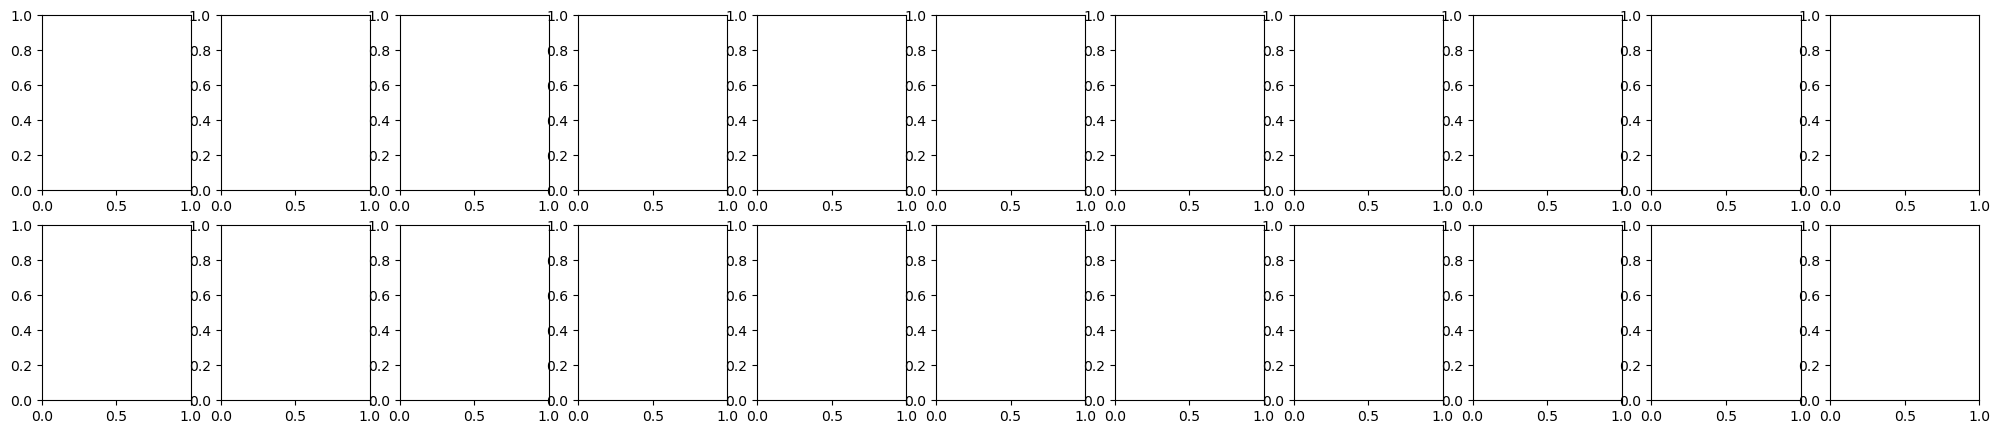

In [ ]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    # compare interps across seeds
    layer_idx=5
    save_dir = f'{rt}/{dataset_type}/interpretability_compare_seeds/'
    for i, row in dfo_prep.iterrows():
        accession_id = row['accession']
        label_number = row['label']
        lab_type = row['type']
        true_label = row['true_label']

        for method in ['IntegratedGradients', 'Occlusion', 'GuidedBackprop']:
        #for method in ['GuidedBackprop']:
            new_path = os.path.join(save_dir, lab_type, str(accession_id), f'{method}_explain{label_number}.png')
            os.makedirs(os.path.dirname(new_path), exist_ok=True)
            
            fig, axs = plt.subplots(2,11, figsize = (25,5))
            print(f"Processing {accession_id}, label={true_label}, explaining {label_number}, type {lab_type}, method {method}")
            sag_probs = []
            cor_probs = []
            
            for seed_idx, model_to_use in enumerate(models_list):
                print(f'Seed {seed_idx}')

                if uses_mipview:
                    cor_img, cor_attribution, cor_prob = calculate_interpretability_for_study(accession_id, 'cor', label_number, type=method, layer_to_iterate=target_layer, device='cuda',
                        model_to_use=model_to_use, model_idx = [seed_idx])
                    sag_img, sag_attribution, sag_prob = calculate_interpretability_for_study(accession_id, 'sag', label_number, type=method, layer_to_iterate=target_layer, device='cuda',
                        model_to_use=model_to_use, model_idx = [seed_idx])
                    visualize_interpretability(cor_img, cor_attribution, cor_prob, fig, axs[0,seed_idx+1], type=method, alpha=0.7)
                    visualize_interpretability(sag_img, sag_attribution, sag_prob, fig, axs[1,seed_idx+1], type=method, alpha=0.7)
                    
                    cor_probs.append(cor_prob)
                    sag_probs.append(sag_prob)
                    
                else:
                    cor_img, cor_attribution, cor_prob = calculate_interpretability_for_study(accession_id, None, label_number, type=method, layer_to_iterate=target_layer, device='cuda',
                        model_to_use=model_to_use, model_idx = [seed_idx])
                    visualize_interpretability(cor_img, cor_attribution, cor_prob, fig, axs[0,seed_idx+1], type=method, alpha=0.7)
                    sag_img = cor_img[cor_img.shape[0]//2 : -1,:,:]
                    cor_img = cor_img[:cor_img.shape[0]//2,:,:]
                    cor_probs.append(cor_prob)
                    sag_probs.append(cor_prob)
                
                if seed_idx == 0:
                    axs[0,0].imshow(cor_img)
                    axs[1,0].imshow(sag_img)
            
            for ii in range(2):
                for jj in range(11):
                    axs[ii, jj].axis('off')

            # round all floats in cor_probs to 2 places
            cor_probs = [float(round(prob, 2)) for prob in cor_probs]
            sag_probs = [float(round(prob, 2)) for prob in sag_probs]
            if uses_mipview:
                fig.suptitle(f'{method} - accession {accession_id}, label={true_label}, explaining {label_number}, corprobs (mean {np.mean(cor_probs):.2f})= {cor_probs}, sagprobs (mean {np.mean(sag_probs):.2f})= {sag_probs}')
            else:
                probs = cor_probs
                fig.suptitle(f'{method} - accession {accession_id}, label={true_label}, explaining {label_number}, probs (mean {np.mean(probs):.2f})= {probs}')
            fig.tight_layout()
            fig.savefig(new_path, dpi=600)
            
            #fig.suptitle(f'{method} - accession {accession_id}, label={true_label}, explaining {label_number}, corprob= {cor_prob:.2f}, sagprob= {sag_prob:.2f}')
        '''
            fig.show()
            #fig.savefig(new_path, dpi=600)

            
            #fig.savefig(new_path, dpi=600)
        '''